In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap
import pyBigWig

**Finding top peak signal for cycle 1 removed calls**

In [48]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_diffflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh-0.5_to1thresh0.5_cycle1_CT20220314.npz'
cycle1_np_file = np.load(filename)
cycle1_biosample_inds_to_1 = cycle1_np_file['biosample_inds_to_1']
cycle1_DHS_inds_to_1 = cycle1_np_file['DHS_inds_to_1']
cycle1_biosample_inds_to_0 = cycle1_np_file['biosample_inds_to_0']
cycle1_DHS_inds_to_0 = cycle1_np_file['DHS_inds_to_0']

In [54]:
cycle1_flat_inds_removed = np.int64(cycle1_DHS_inds_to_0) + (n_DHSs * np.int64(cycle1_biosample_inds_to_0))
cycle1_flat_inds_added = np.int64(cycle1_DHS_inds_to_1) + (n_DHSs * np.int64(cycle1_biosample_inds_to_1))

In [3]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)
DHS_metadata['start'] = DHS_metadata['start'].astype(int)
DHS_metadata['end'] = DHS_metadata['end'].astype(int)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [51]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220215.npy'
DHS_peak_signal_array = np.load(file)

In [52]:
n_biosamples, n_DHSs = DHS_peak_signal_array.shape

In [6]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [7]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')

In [8]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

official_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])
color = np.array(color)[official_order]
comps = np.array(comps)[official_order]

In [22]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_diffflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh-0.5_to1thresh0.5_cycle1_CT20220314.npz'
cycle1_np_file = np.load(filename)
cycle1_diff_flat = cycle1_np_file['diff_flat_array']

**Histogram of delta values**

In [23]:
print(len(cycle1_diff_flat[cycle1_diff_flat<-0.5]))
print(len(cycle1_diff_flat[cycle1_diff_flat>0.5]))

34763776
7800804


In [122]:
len(cycle1_diff_flat)

2632861234

In [2]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_diffflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh-0.5_to1thresh0.5_cycle1_CT20220314.npz'
cycle1_np_file = np.load(filename)
cycle1_diff_flat = cycle1_np_file['diff_flat_array']

cycle1_diff_flat_for_plotting = cycle1_diff_flat
del cycle1_diff_flat

#values for bins of histogram
bins = np.round(np.arange(-1, 2, 0.01), 3)
value_for_bins_cycle1 = np.zeros(300)
#counting and removing delta=0 values first since this is the majority of the data
mask = (cycle1_diff_flat_for_plotting>=bins[100]) & (cycle1_diff_flat_for_plotting<bins[101])
value_for_bins_cycle1[100] = len(cycle1_diff_flat_for_plotting[mask])
cycle1_diff_flat_for_plotting = cycle1_diff_flat_for_plotting[~mask]
for i in range(len(bins)-1):
    mask = (cycle1_diff_flat_for_plotting>=bins[i]) & (cycle1_diff_flat_for_plotting<bins[i+1])
    value_for_bins_cycle1[i] += len(cycle1_diff_flat_for_plotting[mask])
    cycle1_diff_flat_for_plotting = cycle1_diff_flat_for_plotting[~mask]
    
value_for_bins_cycle1 = value_for_bins_cycle1.astype(int)
del cycle1_diff_flat_for_plotting

In [3]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_diffflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh-0.5_to1thresh0.5_cycle2_CT20220314.npz'
cycle2_np_file = np.load(filename)
cycle2_diff_flat = cycle2_np_file['diff_flat_array']

cycle2_diff_flat_for_plotting = cycle2_diff_flat
del cycle2_diff_flat

#values for bins of histogram
bins = np.round(np.arange(-1, 2, 0.01), 3)
value_for_bins_cycle2 = np.zeros(300)
#counting and removing delta=0 values first since this is the majority of the data
mask = (cycle2_diff_flat_for_plotting>=bins[100]) & (cycle2_diff_flat_for_plotting<bins[101])
value_for_bins_cycle2[100] = len(cycle2_diff_flat_for_plotting[mask])
cycle2_diff_flat_for_plotting = cycle2_diff_flat_for_plotting[~mask]
for i in range(len(bins)-1):
    mask = (cycle2_diff_flat_for_plotting>=bins[i]) & (cycle2_diff_flat_for_plotting<bins[i+1])
    value_for_bins_cycle2[i] += len(cycle2_diff_flat_for_plotting[mask])
    cycle2_diff_flat_for_plotting = cycle2_diff_flat_for_plotting[~mask]
    
value_for_bins_cycle2 = value_for_bins_cycle2.astype(int)
del cycle2_diff_flat_for_plotting

In [4]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_diffflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh-0.5_to1thresh0.5_cycle3_CT20220314.npz'
cycle3_np_file = np.load(filename)
cycle3_diff_flat = cycle3_np_file['diff_flat_array']

cycle3_diff_flat_for_plotting = cycle3_diff_flat
del cycle3_diff_flat

#values for bins of histogram
bins = np.round(np.arange(-1, 2, 0.01), 3)
value_for_bins_cycle3 = np.zeros(300)
#counting and removing delta=0 values first since this is the majority of the data
mask = (cycle3_diff_flat_for_plotting>=bins[100]) & (cycle3_diff_flat_for_plotting<bins[101])
value_for_bins_cycle3[100] = len(cycle3_diff_flat_for_plotting[mask])
cycle3_diff_flat_for_plotting = cycle3_diff_flat_for_plotting[~mask]
for i in range(len(bins)-1):
    mask = (cycle3_diff_flat_for_plotting>=bins[i]) & (cycle3_diff_flat_for_plotting<bins[i+1])
    value_for_bins_cycle3[i] += len(cycle3_diff_flat_for_plotting[mask])
    cycle3_diff_flat_for_plotting = cycle3_diff_flat_for_plotting[~mask]
    
value_for_bins_cycle3 = value_for_bins_cycle3.astype(int)
del cycle3_diff_flat_for_plotting

Text(0.5, 1.08, 'Delta Values for Every Call\nDelta Threshold Flip, Threshold=-0.5/0.5')

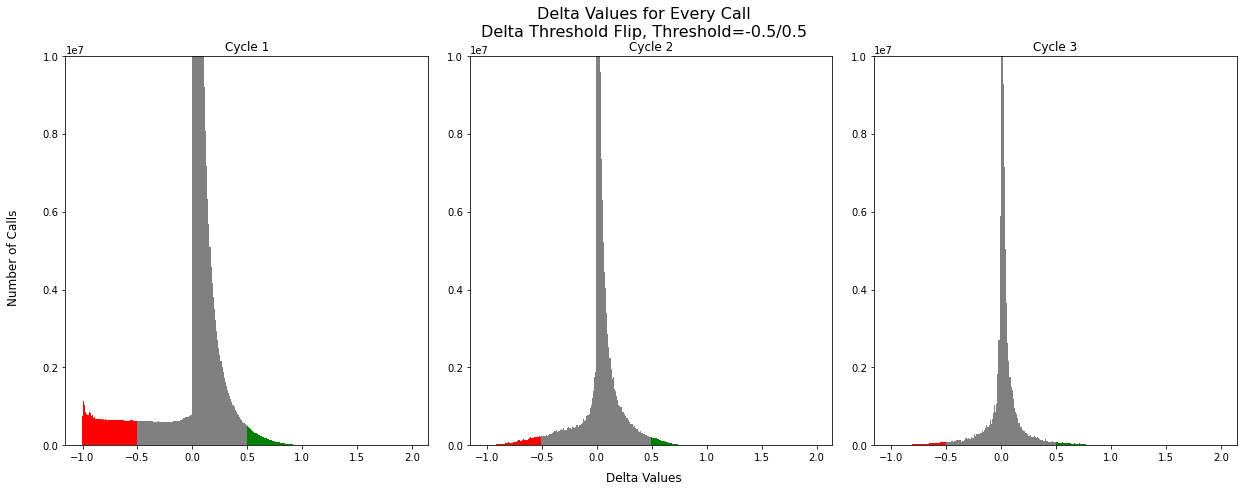

In [9]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,6))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes[0].bar(bins[50:150], value_for_bins_cycle1[50:150], width=0.01, color='grey')
axes[0].bar(bins[:50], value_for_bins_cycle1[:50], width=0.01, color='red')
axes[0].bar(bins[150:], value_for_bins_cycle1[150:], width=0.01, color='green')

axes[1].bar(bins[50:150], value_for_bins_cycle2[50:150], width=0.01, color='grey')
axes[1].bar(bins[:50], value_for_bins_cycle2[:50], width=0.01, color='red')
axes[1].bar(bins[150:], value_for_bins_cycle2[150:], width=0.01, color='green')

axes[2].bar(bins[50:150], value_for_bins_cycle3[50:150], width=0.01, color='grey')
axes[2].bar(bins[:50], value_for_bins_cycle3[:50], width=0.01, color='red')
axes[2].bar(bins[150:], value_for_bins_cycle3[150:], width=0.01, color='green')


axes[0].set_title('Cycle 1')
axes[1].set_title('Cycle 2')
axes[2].set_title('Cycle 3')

axes[0].set_ylim([0, 10000000])
axes[1].set_ylim([0, 10000000])
axes[2].set_ylim([0, 10000000])

    
# plt.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
fig.text(0.5, -0.02, 'Delta Values', ha='center', fontsize=12)
fig.text(-0.02, 0.5, 'Number of Calls', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Delta Values for Every Call\nDelta Threshold Flip, Threshold=-0.5/0.5', fontsize=16, x=0.5, y=1.08)

Text(0.5, 1.0, 'Delta Values for Every Call in Cycle 1\nDelta Threshold Flip, Threshold=-0.5/0.5')

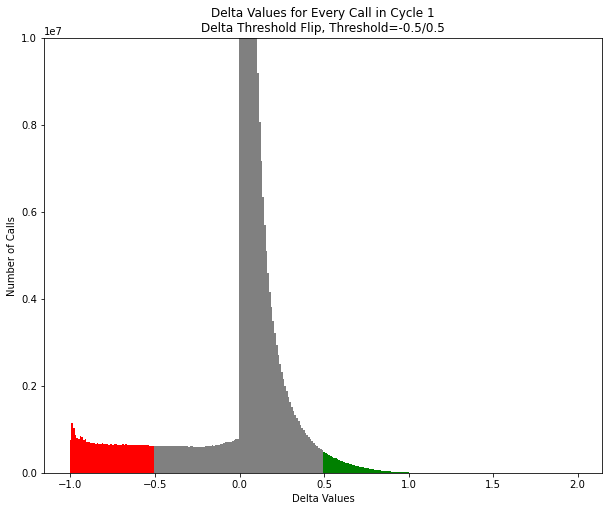

In [47]:
fig = plt.figure(figsize=(10,8))
fig.patch.set_facecolor('white')

plt.bar(bins[50:150], value_for_bins[50:150], width=0.01, color='grey')
plt.bar(bins[:50], value_for_bins[:50], width=0.01, color='red')
plt.bar(bins[150:], value_for_bins[150:], width=0.01, color='green')
# plt.yscale('log')
plt.xlabel('Delta Values')
plt.ylabel('Number of Calls')
plt.ylim([0, 10000000])
plt.title('Delta Values for Every Call in Cycle 1\nDelta Threshold Flip, Threshold=-0.5/0.5')

**Fraction of flipped peaks that have delta value of opposite polarity in neighboring DHS**

In [57]:
#finding flat inds of neighboring DHSs to changed calls
cycle1_flipped_call_flat_inds = np.append(cycle1_flat_inds_added, cycle1_flat_inds_removed)
cycle1_flipped_call_flat_inds_1right = cycle1_flipped_call_flat_inds + 1
cycle1_flipped_call_flat_inds_2right = cycle1_flipped_call_flat_inds + 2
cycle1_flipped_call_flat_inds_1left = cycle1_flipped_call_flat_inds - 1
cycle1_flipped_call_flat_inds_2left = cycle1_flipped_call_flat_inds - 2

#finding delta vals for center DHS and neighbors
cycle1_flipped_call_flat_inds_left_to_right = np.array([cycle1_flipped_call_flat_inds_2left, 
                                                      cycle1_flipped_call_flat_inds_1left, 
                                                      cycle1_flipped_call_flat_inds,
                                                      cycle1_flipped_call_flat_inds_1right, 
                                                      cycle1_flipped_call_flat_inds_2right])
cycle1_flipped_call_delta_left_to_right = cycle1_diff_flat[cycle1_flipped_call_flat_inds_left_to_right]

In [62]:
#finding where center DHS and neighboring DHSs have opposite polarity in delta values
neg_thresh = -0.5
pos_thresh = 0.5
# cycle1_centerpos_neighborneg = ((cycle1_flipped_call_delta_left_to_right[2] > 0) & (cycle1_flipped_call_delta_left_to_right[0] < neg_thresh) | 
#                                (cycle1_flipped_call_delta_left_to_right[2] > 0) & (cycle1_flipped_call_delta_left_to_right[1] < neg_thresh) |
#                                (cycle1_flipped_call_delta_left_to_right[2] > 0) & (cycle1_flipped_call_delta_left_to_right[3] < neg_thresh) |
#                                (cycle1_flipped_call_delta_left_to_right[2] > 0) & (cycle1_flipped_call_delta_left_to_right[4] < neg_thresh))

# cycle1_centerneg_neighborpos = ((cycle1_flipped_call_delta_left_to_right[2] < 0) & (cycle1_flipped_call_delta_left_to_right[0] > pos_thresh) | 
#                                (cycle1_flipped_call_delta_left_to_right[2] < 0) & (cycle1_flipped_call_delta_left_to_right[1] > pos_thresh) |
#                                (cycle1_flipped_call_delta_left_to_right[2] < 0) & (cycle1_flipped_call_delta_left_to_right[3] > pos_thresh) |
#                                (cycle1_flipped_call_delta_left_to_right[2] < 0) & (cycle1_flipped_call_delta_left_to_right[4] > pos_thresh))

cycle1_centerpos_neighborneg = ((cycle1_flipped_call_delta_left_to_right[2] > 0) & (cycle1_flipped_call_delta_left_to_right[1] < neg_thresh) |
                               (cycle1_flipped_call_delta_left_to_right[2] > 0) & (cycle1_flipped_call_delta_left_to_right[3] < neg_thresh))

cycle1_centerneg_neighborpos = ((cycle1_flipped_call_delta_left_to_right[2] < 0) & (cycle1_flipped_call_delta_left_to_right[1] > pos_thresh) |
                               (cycle1_flipped_call_delta_left_to_right[2] < 0) & (cycle1_flipped_call_delta_left_to_right[3] > pos_thresh))

#inds relative to cycle1_flipped_call_flat_inds
cycle1_centerpos_neighborneg_inds = np.arange(len(cycle1_centerpos_neighborneg))[cycle1_centerpos_neighborneg]
cycle1_centerneg_neighborpos_inds = np.arange(len(cycle1_centerneg_neighborpos))[cycle1_centerneg_neighborpos]

print(np.sum(cycle1_centerpos_neighborneg.astype(int)))
print(np.sum(cycle1_centerneg_neighborpos.astype(int)))

443653
456580


In [92]:
#simulation to see how many randomly draw delta values acting as neighbors to added calls 
#are above/below some threshold 
count_list = []
for j in range(10):
    random_delta_list = np.array(random.choices(cycle1_diff_flat, k=len(cycle1_flat_inds_added)*2))
    split1 = random_delta_list[::2]
    split2 = random_delta_list[1::2]
    split1_hit_inds = np.where(split1 < -0.5)[0]
    split2_hit_inds = np.where(split2 < -0.5)[0]
    unique_hits = np.unique(np.append(split1_hit_inds, split2_hit_inds))
    count_list.append(len(unique_hits))
print(np.mean(count_list))
print(len(cycle1_flat_inds_added))

204552.9
7800804


In [93]:
#simulation to see how many randomly draw delta values acting as neighbors to removed calls 
#are above/below some threshold 
count_list = []
for j in range(10):
    random_delta_list = np.array(random.choices(cycle1_diff_flat, k=len(cycle1_flat_inds_removed)*2))
    split1 = random_delta_list[::2]
    split2 = random_delta_list[1::2]
    split1_hit_inds = np.where(split1 > 0.5)[0]
    split2_hit_inds = np.where(split2 > 0.5)[0]
    unique_hits = np.unique(np.append(split1_hit_inds, split2_hit_inds))
    count_list.append(len(unique_hits))
print(np.mean(count_list))
print(len(cycle1_flat_inds_removed))

205665.0
34763776
